In [ ]:
!pip install scikit-learn
!pip install seaborn
!pip install keras-tuner

In [ ]:
# Importa as bibliotecas necessárias
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input, Conv2D, MaxPooling2D, Dropout, LeakyReLU 
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import keras_tuner as kt
import os
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Define o caminho base do dataset como pasta atual, caso esteja em outra pasta, alterar aqui
BASE_PATH = '.'

#Define as dimensões da imagem
IMG_HEIGHT = 224
IMG_WIDTH = 224

#Cria os geradores de dados para treino, validação e teste
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
#Carrega os dados de treino
train_generator = train_datagen.flow_from_directory(
    os.path.join(BASE_PATH, 'train'),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=32,
    class_mode='binary'
)

#Carrega os dados de validação
validation_generator = val_datagen.flow_from_directory(
    os.path.join(BASE_PATH, 'val'),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=32,
    class_mode='binary'
)

#Carrega os dados de teste
test_generator = test_datagen.flow_from_directory(
    os.path.join(BASE_PATH, 'test'),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 2400 images belonging to 2 classes.
Found 300 images belonging to 2 classes.
Found 300 images belonging to 2 classes.


In [ ]:
def build_model(hp):
    inputs = Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = inputs

    #Parte Convolucional
    for i in range(hp.Int('num_conv_layers', 2, 4, step=1)):
        x = Conv2D(
            filters=hp.Int(f'filters_{i}', min_value=32, max_value=128, step=32),
            #Filtro de tamanho fixo 3x3 com ativação ReLU e padding 'same'
            kernel_size=(3, 3),
            activation='relu',
            padding='same'
        )(x)
        #Camada de MaxPooling2D com tamanho 2x2
        x = MaxPooling2D(pool_size=(2, 2))(x)

    #Camada de Global Average Pooling para reduzir a dimensionalidade
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    #Camada de Dropout com taxa entre 0.2 e 0.5 para evitar overfitting
    x = Dropout(hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1))(x)

    #Parte Densa
    for i in range(hp.Int('n_hidden_layers', min_value=1, max_value=3, step=1)):
        x = Dense(
            units=hp.Int(f'n_neurons_{i}', min_value=64, max_value=256, step=64)
        )(x)
        
        #Escolha da função de ativação
        activation_choice = hp.Choice(f'dense_activation_{i}', values=['relu', 'tanh', 'leaky_relu'])
        if activation_choice == 'leaky_relu':
            x = LeakyReLU(alpha=0.2)(x)
        elif activation_choice == 'tanh':
            x = tf.keras.activations.tanh(x)
        else: #relu
            x = tf.keras.activations.relu(x)

    #A camada de saída tem 1 neurônio com ativação sigmóide para classificação binária        
    predictions = Dense(1, activation='sigmoid')(x)
    model = Model(inputs=inputs, outputs=predictions)

    #Otimizadores e taxa de aprendizado
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    optimizer_choice = hp.Choice('optimizer', values=['adam', 'nadam', 'sgd'])
    
    if optimizer_choice == 'adam':
        optimizer = tf.keras.optimizers.Adam(learning_rate=hp_learning_rate)
    elif optimizer_choice == 'nadam':
        optimizer = tf.keras.optimizers.Nadam(learning_rate=hp_learning_rate)
    else: #sgd
        hp_momentum = hp.Choice('momentum', values=[0.9, 0.95])
        optimizer = tf.keras.optimizers.SGD(learning_rate=hp_learning_rate, momentum=hp_momentum)

    #Compila o modelo
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
#Instancia o tuner com o Hyperband para a busca de hiperparâmetros
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=10,
    factor=3,
    directory='my_dir',
    project_name='cnn_final'
)

#Configura um EarlyStopping para parar o treinamento se a validação não melhorar
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

#Passos da época para a busca de hiperparâmetros
steps_per_epoch = 30
validation_steps = 15

print("Iniciando busca de hiperparâmetros...")

#Executa a busca de hiperparâmetros com o Hyperband
tuner.search(train_generator,
             steps_per_epoch=steps_per_epoch,
             epochs=5,
             validation_data=validation_generator,
             validation_steps=validation_steps,
             callbacks=[stop_early])

#Exibe os resultados
tuner.results_summary()

Trial 30 Complete [00h 05m 19s]
val_accuracy: 0.6933333277702332

Best val_accuracy So Far: 0.7599999904632568
Total elapsed time: 01h 42m 27s
Results summary
Results in my_dir\cnn_final
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0024 summary
Hyperparameters:
num_conv_layers: 4
filters_0: 64
filters_1: 96
dropout: 0.2
n_hidden_layers: 1
n_neurons_0: 256
dense_activation_0: relu
learning_rate: 0.001
optimizer: adam
filters_2: 64
n_neurons_1: 256
dense_activation_1: tanh
n_neurons_2: 256
dense_activation_2: relu
momentum: 0.9
filters_3: 96
tuner/epochs: 10
tuner/initial_epoch: 4
tuner/bracket: 1
tuner/round: 1
tuner/trial_id: 0023
Score: 0.7599999904632568

Trial 0025 summary
Hyperparameters:
num_conv_layers: 4
filters_0: 96
filters_1: 32
dropout: 0.30000000000000004
n_hidden_layers: 1
n_neurons_0: 64
dense_activation_0: relu
learning_rate: 0.001
optimizer: nadam
filters_2: 32
n_neurons_1: 192
dense_activation_1: relu
n_neurons_2: 256
dense_activation_2

In [7]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Melhores hiperparâmetros encontrados:")
print(best_hps.values)

Melhores hiperparâmetros encontrados:
{'num_conv_layers': 4, 'filters_0': 64, 'filters_1': 96, 'dropout': 0.2, 'n_hidden_layers': 1, 'n_neurons_0': 256, 'dense_activation_0': 'relu', 'learning_rate': 0.001, 'optimizer': 'adam', 'filters_2': 64, 'n_neurons_1': 256, 'dense_activation_1': 'tanh', 'n_neurons_2': 256, 'dense_activation_2': 'relu', 'momentum': 0.9, 'filters_3': 96, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0023'}


In [ ]:
#Constrói o melhor modelo
best_model = tuner.hypermodel.build(best_hps)

In [ ]:
#Treina o modelo final
print("\nTreinando o modelo final com os melhores parâmetros...")
best_model.fit(train_generator, epochs=100, validation_data=validation_generator)


Treinando o modelo final com os melhores parâmetros...


Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 117s 2s/step - accuracy: 0.5779 - loss: 0.6574 - val_accuracy: 0.7567 - val_loss: 0.5266
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.7300 - loss: 0.5413 - val_accuracy: 0.7400 - val_loss: 0.5000
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.7517 - loss: 0.5192 - val_accuracy: 0.7567 - val_loss: 0.4918
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.7608 - loss: 0.4982 - val_accuracy: 0.7233 - val_loss: 0.5641
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.7729 - loss: 0.4855 - val_accuracy: 0.7533 - val_loss: 0.4783
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.7750 - loss: 0.4814 - val_accuracy: 0.7600 - val_loss: 0.4919
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.7979 - loss: 0.4361 - val_accuracy: 0.7733 - val_loss: 0.4550
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.8062 - loss: 0.4119 - val_accuracy: 0.

In [ ]:
#Avalia o melhor modelo no conjunto de teste
print("\nAvaliando o melhor modelo no conjunto de teste...")
loss, acc = best_model.evaluate(test_generator)
print(f"Acurácia no conjunto de teste: {acc * 100:.2f}%")


Avaliando o melhor modelo no conjunto de teste...
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - accuracy: 0.9067 - loss: 1.0067
Acurácia no conjunto de teste: 90.67%



Gerando predições para o conjunto de teste...
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 338ms/step


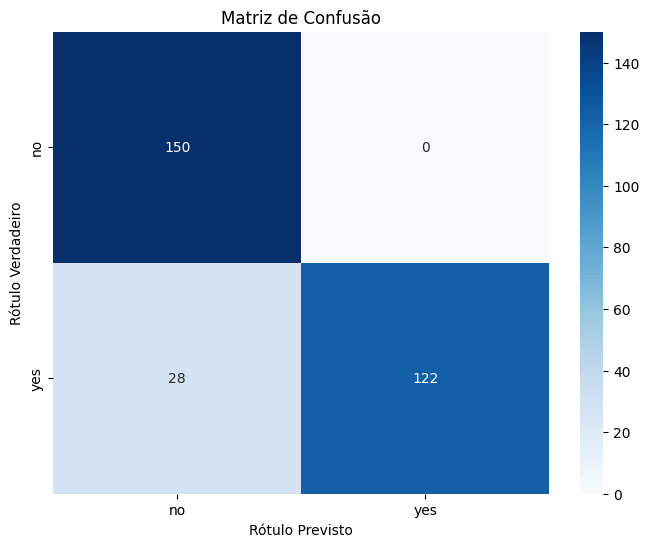


Relatório de Classificação:
              precision    recall  f1-score   support

          no       0.84      1.00      0.91       150
         yes       1.00      0.81      0.90       150

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.91       300
weighted avg       0.92      0.91      0.91       300



In [ ]:
#Obtem os rótulos verdadeiros do conjunto de teste
test_generator.reset()
y_true = test_generator.classes

#Obtem as predições do modelo no conjunto de teste
print("\nGerando predições para o conjunto de teste...")
y_pred_probs = best_model.predict(test_generator)

#Converte as probabilidades em classes binárias (0 ou 1)
y_pred = (y_pred_probs > 0.5).astype("int32")

y_pred = y_pred.flatten()

#Gera a matriz de confusão
cm = confusion_matrix(y_true, y_pred)
class_names = list(test_generator.class_indices.keys())

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusão')
plt.ylabel('Rótulo Verdadeiro')
plt.xlabel('Rótulo Previsto')
plt.show()

# Exibe métricas adicionais
print("\nRelatório de Classificação:")
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=class_names))

In [12]:
# Salva o modelo completo
best_model.save('modelo_cnn.keras')
print("Modelo completo salvo como 'modelo_cnn.keras'")

Modelo completo salvo como 'modelo_cnn.keras'
